# 10 · Optimiseurs sous contraintes : OC, MMA

*Notebook 10 du cours. Il suppose les notebooks 8 (OC) et 9 (filtre, projection, continuation, boucle `run`).*

Au notebook 8, l'OC a suffi : une compliance à minimiser et **une** contrainte de volume. Le projet combinera bientôt plusieurs objectifs ou contraintes (compliance, aérodynamique, surplomb). Il faut un optimiseur **général**. Ce notebook compare trois méthodes sur des problèmes de difficulté croissante, à solution connue d'abord, puis sur la poutre MBB :

- la **descente de gradient projetée**, la plus simple ;
- le **critère d'optimalité (OC)**, déjà vu ;
- la **méthode des asymptotes mobiles (MMA)** de Svanberg, standard de l'optimisation topologique.

**Plan.**
1. Ce que l'OC suppose, et ce qui se passe quand ce n'est plus vrai ;
2. Les conditions d'optimalité (KKT) avec bornes : l'outil de vérification ;
3. La descente de gradient projetée ;
4. MMA : approximations convexes séparables, asymptotes, problème dual ;
5. Validation de MMA sur des problèmes à solution connue ;
6. La poutre MBB : les trois méthodes ;
7. MMA avec continuation : pourquoi le reset est indispensable ;
8. Un autre problème : minimiser le volume sous une limite de compliance ;
9. Bilan.

Ce notebook promeut dans `src` : `optim/mma.py::MMA` (port maison, une ou plusieurs contraintes) et complète `OC`. Contrats : C-OPT-01 (bornes exactes), C-OPT-03 (volume tenu, moitié MMA).

In [1]:
import sys, time, inspect
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.optimize import minimize

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))

from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.mma import MMA
from aeroptimizer.optim.oc import OC
from aeroptimizer.problem import ComplianceProblem

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def montre(ax, rho, shape, titre=""):
    ax.imshow(np.asarray(rho).reshape(shape).T, origin="lower", cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([])

grise = lambda r: float(((np.asarray(r) > 0.1) & (np.asarray(r) < 0.9)).mean())

## 1. Ce que l'OC suppose

Le cadre commun est

$$
\min_{\mathbf x\in[0,1]^n}\ f(\mathbf x)\qquad\text{sous}\qquad g_i(\mathbf x)\le0,\quad i=1,\dots,m,
$$

et tous nos optimiseurs ont la même interface `step(x, f, df, g, dg) -> x_nouveau` (`df` de taille $n$, `g` de taille $m$, `dg` de taille $m\times n$). L'OC du notebook 8 repose sur trois hypothèses qu'on n'avait pas besoin de remarquer :

1. **une seule contrainte** ($m=1$) ;
2. l'objectif **décroît** quand on ajoute de la matière : $\partial f/\partial x_e\le0$ ;
3. la contrainte **croît** avec la matière : $\partial g/\partial x_e>0$.

Le multiplicateur de $B_e=-\partial f/\partial x_e\,/\,(\Lambda\,\partial g/\partial x_e)$ n'a de sens que si ces signes sont ceux-là. Voici un problème trivial, une projection de $\mathbf c$ sur la boîte $[0,1]^n$ avec **la contrainte renversée** $\sum x_e\ge b$ (on exige *au moins* un volume), pour lequel la solution est $x_e=\operatorname{clip}(c_e+\lambda/2,0,1)$, $\lambda$ trouvé par bissection : on connaît donc la réponse. À l'optimum, les gradients ont les signes **opposés** à ceux de l'OC.

In [2]:
rng = np.random.default_rng(0)
n = 30
c = rng.uniform(0.0, 0.4, n)                       # cibles basses : sum(c) = 6,4 < b -> la contrainte est active
b = 0.6 * n
lo, hi = 0.0, 50.0
for _ in range(200):                               # solution exacte par bissection sur lambda
    lam = 0.5 * (lo + hi)
    lo, hi = (lam, hi) if np.clip(c + lam / 2, 0, 1).sum() < b else (lo, lam)
x_exact = np.clip(c + hi / 2, 0, 1)
print(f"sum(c) = {c.sum():.2f} < b = {b} ; solution exacte : sum(x) = {x_exact.sum():.4f}, objectif {((x_exact - c) ** 2).sum():.4f}")

def resout_qp(opt, n_it=100):
    x = np.full(n, 0.3)
    for _ in range(n_it):
        # f = |x - c|^2 ;  g = 1 - sum(x)/b <= 0 ;  dg = -1/b  (négatif !)
        x = opt.step(x, ((x - c) ** 2).sum(), 2 * (x - c), np.array([1 - x.sum() / b]), -np.ones((1, n)) / b)
    return x

for nom, opt in [("OC", OC()), ("MMA", MMA())]:
    x = resout_qp(opt)
    print(f"{nom:>4} : erreur max à la solution {np.abs(x - x_exact).max():.1e} ; contrainte 1 - sum(x)/b = {1 - x.sum() / b:+.3f}")

sum(c) = 6.41 < b = 18.0 ; solution exacte : sum(x) = 18.0000, objectif 4.4759
  OC : erreur max à la solution 4.9e-01 ; contrainte 1 - sum(x)/b = +0.617
 MMA : erreur max à la solution 6.7e-16 ; contrainte 1 - sum(x)/b = +0.000


L'OC se trompe de moitié (la contrainte reste violée de 62 % : $\sum x_e$ est à 38 % de la cible), sans le moindre message : avec $\partial g/\partial x<0$ la formule $\max(-\partial f,0)/\partial g$ n'a plus de sens. MMA, qui ne fait aucune hypothèse de signe, trouve la solution à la précision machine. Le deuxième exemple, plus important pour le projet, est au §8 (minimiser le volume sous contrainte de compliance : les rôles de $f$ et de $g$ sont échangés).

## 2. Les conditions d'optimalité (KKT) avec bornes

Pour vérifier un optimiseur il faut un critère qui ne dépende pas de lui. Au point $\mathbf x^\star$ (minimum local), il existe des multiplicateurs $\boldsymbol\lambda\ge0$ tels que, avec le gradient du lagrangien $r_j=\partial_jf+\sum_i\lambda_i\,\partial_jg_i$ :

$$
\begin{cases}
r_j=0 & \text{si }0<x_j<1\quad(\text{élément libre}),\\
r_j\ge0 & \text{si }x_j=0\quad(\text{on voudrait diminuer, la borne l'empêche}),\\
r_j\le0 & \text{si }x_j=1,
\end{cases}
\qquad g_i\le0,\quad \lambda_i\,g_i=0 .
$$

La fonction ci-dessous estime $\boldsymbol\lambda$ par moindres carrés sur les éléments libres puis renvoie les violations (relatives à $\max|\partial f|$).

In [3]:
def kkt(x, df, g, dg, tol_bnd=1e-9):
    # multiplicateurs par moindres carrés sur les éléments libres, puis violations normalisées
    x, df, g = np.asarray(x), np.ravel(df), np.ravel(g)
    dg = np.asarray(dg).reshape(len(g), -1)
    libre = (x > tol_bnd) & (x < 1 - tol_bnd)
    actif = g > -1e-7                                  # contraintes actives (g ~ 0)
    lam = np.zeros(len(g))
    if libre.any() and actif.any():
        lam[actif] = np.linalg.lstsq(dg[actif][:, libre].T, -df[libre], rcond=None)[0]
    r = df + lam @ dg
    ech = max(np.abs(df).max(), 1e-300)
    return {"lambda": lam,
            "libres": float(np.abs(r[libre]).max() / ech) if libre.any() else 0.0,
            "borne_0": float(max(0.0, -r[x <= tol_bnd].min()) / ech) if (x <= tol_bnd).any() else 0.0,
            "borne_1": float(max(0.0, r[x >= 1 - tol_bnd].max()) / ech) if (x >= 1 - tol_bnd).any() else 0.0,
            "faisabilite": float(max(0.0, g.max())), "lam_neg": float(max(0.0, -lam.min()))}

x_mma = resout_qp(MMA())
k = kkt(x_mma, 2 * (x_mma - c), np.array([1 - x_mma.sum() / b]), -np.ones((1, n)) / b)
print("MMA, solution du §1 :", {a: round(v, 12) if np.isscalar(v) else v.round(6) for a, v in k.items()})
bruit = 0.01 * rng.standard_normal(n)
libre = (x_exact > 1e-9) & (x_exact < 1 - 1e-9)
bruit[~libre] = 0.0
bruit[libre] -= bruit[libre].mean()                 # perturbation qui garde sum(x) = b : seule l'optimalité est en défaut
x_mauvais = x_exact + bruit
k = kkt(x_mauvais, 2 * (x_mauvais - c), np.array([1 - x_mauvais.sum() / b]), -np.ones((1, n)) / b)
print("point perturbé de 0,01 :", {a: round(v, 4) if np.isscalar(v) else v.round(4) for a, v in k.items()})

MMA, solution du §1 : {'lambda': array([13.9053]), 'libres': 0.0, 'borne_0': 0.0, 'borne_1': 0.0, 'faisabilite': 0.0, 'lam_neg': 0.0}
point perturbé de 0,01 : {'lambda': array([13.9053]), 'libres': 0.0418, 'borne_0': 0.0, 'borne_1': 0.0, 'faisabilite': 0.0, 'lam_neg': 0.0}


Au point exact, toutes les violations sont nulles à la précision machine ; une perturbation de l'ordre de $10^{-2}$ (qui reste faisable) fait monter la violation sur les éléments libres à 0,04 : le critère détecte un point faisable qui n'est pas optimal. Il est valable pour tout optimiseur, et on l'utilise au §6 sur la poutre.

## 3. La descente de gradient projetée

L'idée la plus simple : un pas dans la direction opposée au gradient, puis **projection** sur l'ensemble admissible. Ici l'ensemble est la boîte $[0,1]^n$ intersectée avec la contrainte de volume. La projection s'obtient par bissection sur un décalage $\mu$ : $\mathbf x=\operatorname{clip}(\mathbf y-\mu,0,1)$ avec $\mu$ choisi pour que la contrainte soit tenue (le volume décroît avec $\mu$). Le pas est normalisé : $\mathbf y=\mathbf x-s\,\nabla f/\max|\nabla f|$, de sorte que $s$ est un déplacement maximal par itération, comme `move` pour l'OC.

In [4]:
class PGD:
    # descente de gradient projetée, une contrainte g(x) <= 0 (volume), pas normalisé s
    move = 0.2
    def __init__(self, s): self.s, self.move = s, s
    def reset(self): pass
    def step(self, x, f, df, g, dg, g_of_x=None):
        df = np.ravel(df); dg = np.asarray(dg).reshape(-1)
        y = x - self.s * df / max(np.abs(df).max(), 1e-300)
        gx = g_of_x if g_of_x is not None else (lambda z: float(np.ravel(g)[0] + dg @ (z - x)))
        lo, hi = -2.0, 2.0
        for _ in range(100):                           # bissection sur mu
            mu = 0.5 * (lo + hi)
            lo, hi = (mu, hi) if gx(np.clip(y - mu, 0, 1)) > 0 else (lo, mu)
        return np.clip(y - hi, 0, 1)

# problème du §1 dans le sens où l'OC est valide : sum(x) <= b, cibles hautes (contrainte active)
c2 = np.random.default_rng(0).uniform(0.0, 1.0, n); b2 = 0.3 * n
lo, hi = 0.0, 50.0
for _ in range(200):
    lam = 0.5 * (lo + hi)
    lo, hi = (lam, hi) if np.clip(c2 - lam / 2, 0, 1).sum() > b2 else (lo, lam)
x2 = np.clip(c2 - hi / 2, 0, 1)
print(f"{'méthode':>8} | {'erreur après 20 it.':>20} | {'après 100 it.':>13} | {'après 300 it.':>13}")
for nom, mk in [("PGD s=.05", lambda: PGD(0.05)), ("OC", OC), ("MMA", MMA)]:
    opt, x, err = mk(), np.full(n, 0.5), []
    for _ in range(300):
        x = opt.step(x, 0.0, 2 * (x - c2), np.array([x.sum() / b2 - 1]), np.ones((1, n)) / b2)
        err.append(np.abs(x - x2).max())
    print(f"{nom:>9} | {err[19]:20.1e} | {err[99]:13.1e} | {err[299]:13.1e}")

 méthode |  erreur après 20 it. | après 100 it. | après 300 it.
PGD s=.05 |              3.1e-02 |       8.2e-09 |       2.2e-16
       OC |              1.5e-02 |       1.2e-03 |       1.5e-05


      MMA |              1.3e-08 |       5.6e-16 |       4.4e-16


Dans le cas bien posé pour l'OC (contrainte $\sum x\le b$ active, gradient $2(x-c)\le0$ à l'optimum), les trois convergent. MMA est le plus rapide (précision machine en 100 itérations). La descente projetée converge aussi (ce problème quadratique est bien conditionné et le pas lui convient), et c'est ici l'OC qui est le plus lent ($1{,}5\times10^{-5}$ à 300 itérations). L'ordre n'est donc pas universel ; sur la poutre (§6), où le problème n'est ni convexe ni bien conditionné, le pas de la descente projetée devient critique.

## 4. MMA : approximer par du convexe séparable

À chaque itération, MMA remplace $f$ et chaque $g_i$ par une approximation **séparable et convexe** construite à partir de la valeur et du gradient au point courant $\mathbf x^{k}$ :

$$
f(\mathbf x)\ \approx\ r+\sum_j\Big(\frac{p_j}{U_j-x_j}+\frac{q_j}{x_j-L_j}\Big),\qquad L_j<x_j<U_j,
$$

avec $p_j=(U_j-x^k_j)^2\max(\partial_jf,0)$ et $q_j=(x^k_j-L_j)^2\max(-\partial_jf,0)$ (plus une petite régularisation pour que $p_j,q_j>0$), et $r$ fixé pour que la valeur coïncide en $\mathbf x^k$. Les nombres $L_j$ et $U_j$ sont les **asymptotes** : plus elles sont proches de $x^k_j$, plus l'approximation est « conservative » (elle remonte vite loin de $x^k_j$ et bride le pas), plus elles sont lointaines, plus elle ressemble à la linéarisation. Les asymptotes **bougent** : si une variable oscille d'une itération à l'autre, on les rapproche (facteur 0,7) ; si elle progresse régulièrement dans le même sens, on les éloigne (facteur 1,2). C'est l'âme de MMA : un pas de confiance adaptatif sans recherche de pas.

Le sous-problème est séparable et convexe. Pour des multiplicateurs $\boldsymbol\lambda\ge0$ fixés, chaque variable se minimise toute seule en formule fermée, $x_j(\boldsymbol\lambda)=\operatorname{clip}\!\big((\sqrt{p_j}L_j+\sqrt{q_j}U_j)/(\sqrt{p_j}+\sqrt{q_j})\big)$ avec $p_j,q_j$ cumulés sur le lagrangien. Il reste à maximiser la **fonction duale**, concave et à $m$ variables seulement : une bissection pour $m=1$, L-BFGS-B pour $m>1$. Le coût du sous-problème est donc négligeable devant la résolution éléments finis.

**Une dimension, pour voir.** On approche $f(x)=(x-0{,}3)^2+0{,}3\sin(8x)$ en $x^k=0{,}5$ avec trois couples d'asymptotes.

asymptotes ±0.25 : valeur -2.8e-17, dérivée -3.8e-11 d'écart en x^k
asymptotes ±0.6 : valeur -2.8e-17, dérivée -1.1e-11 d'écart en x^k
asymptotes ±3.0 : valeur +8.3e-17, dérivée -6.6e-11 d'écart en x^k


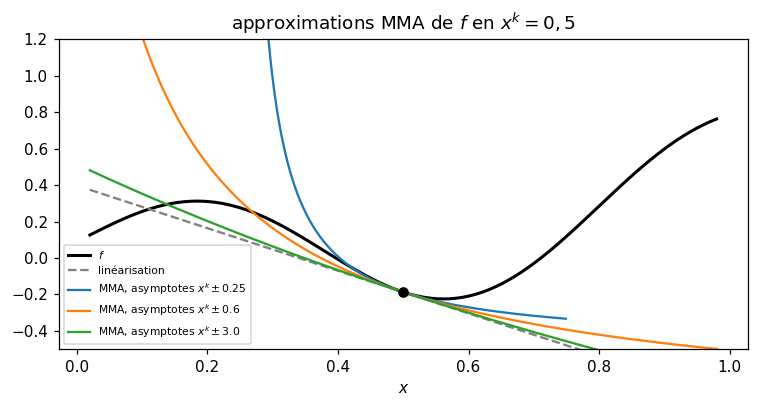

In [5]:
f1 = lambda x: (x - 0.3) ** 2 + 0.3 * np.sin(8 * x)
df1 = lambda x: 2 * (x - 0.3) + 2.4 * np.cos(8 * x)
x0 = 0.5
xs = np.linspace(0.02, 0.98, 400)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(xs, f1(xs), "k", lw=2, label="$f$")
ax.plot(xs, f1(x0) + df1(x0) * (xs - x0), "grey", ls="--", label="linéarisation")
for demi, col in [(0.25, "C0"), (0.6, "C1"), (3.0, "C2")]:
    L, U = x0 - demi, x0 + demi
    p, q = (U - x0) ** 2 * max(df1(x0), 0), (x0 - L) ** 2 * max(-df1(x0), 0)
    r0 = f1(x0) - p / (U - x0) - q / (x0 - L)
    approx = lambda x: r0 + p / (U - x) + q / (x - L)
    ax.plot(xs[(xs > L) & (xs < U)], approx(xs[(xs > L) & (xs < U)]), col, label=f"MMA, asymptotes $x^k\\pm{demi}$")
    print(f"asymptotes ±{demi} : valeur {approx(x0) - f1(x0):+.1e}, dérivée {(approx(x0 + 1e-6) - approx(x0 - 1e-6)) / 2e-6 - df1(x0):+.1e} d'écart en x^k")
ax.plot([x0], [f1(x0)], "ko"); ax.set(ylim=(-0.5, 1.2), xlabel="$x$", title="approximations MMA de $f$ en $x^k=0,5$"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

Les trois approximations ont la même valeur et la même dérivée en $x^k$ (à $10^{-10}$ près), mais leur courbure diffère : **asymptotes proches = forte courbure = petit pas**, asymptotes lointaines = presque la droite tangente. La linéarisation seule n'a pas de minimum (elle descend à l'infini) ; l'approximation convexe en a un, et c'est ce qui rend le sous-problème bien posé.

Voici le code (`optim/mma.py`) : le calcul des asymptotes, des coefficients, du dual.

In [6]:
print(inspect.getsource(MMA.step))

    def step(
        self, x: np.ndarray, f: float, df: np.ndarray, g: np.ndarray, dg: np.ndarray, g_of_x=None  # noqa: ANN001
    ) -> np.ndarray:
        """`g_of_x` (exact constraint evaluator, used by OC) is accepted and ignored."""
        x = np.asarray(x, dtype=float)
        n = x.size
        g = np.ravel(np.asarray(g, dtype=float))
        dg = np.asarray(dg, dtype=float).reshape(-1, n)
        df = np.asarray(df, dtype=float).reshape(n)
        if g.size != self.m or dg.shape[0] != self.m:
            raise ConfigError(f"MMA built for {self.m} constraint(s), got {g.size}")
        s_f = 1.0 / max(float(np.abs(df).max()), 1e-300)
        s_g = 1.0 / np.maximum(np.abs(dg).max(axis=1), 1e-300)
        df, g, dg = df * s_f, g * s_g, dg * s_g[:, None]

        low, upp = self._asymptotes(x)
        alpha = np.maximum.reduce([low + 0.1 * (x - low), np.zeros(n), x - self.move])
        beta = np.minimum.reduce([upp - 0.1 * (upp - x), np.ones(n), x + self.move])
        ul, xl = up

## 5. Validation de MMA sur des problèmes à solution connue

Trois tests, avec chaque fois une référence indépendante :
1. **ressorts en série** (le problème analytique du notebook 8, SIMP $p=2$) : solution $\rho_e\propto a_e^{1/3}$ ;
2. **moindres carrés avec bornes et une contrainte** : solution $\operatorname{clip}(c-\lambda/2)$ par bissection ;
3. **deux contraintes** (ce que l'OC ne sait pas faire) : référence SLSQP de SciPy.

In [7]:
# 1) ressorts en série
N, V = 10, 0.4
a = np.linspace(1.0, 4.0, N)
exact = N * V * a ** (1 / 3) / (a ** (1 / 3)).sum()
mma, x, err = MMA(), np.full(N, V), []
for _ in range(60):
    x = mma.step(x, 0.0, -2 * a / x**3, np.array([x.mean() / V - 1]), np.full((1, N), 1 / (N * V)))
    err.append(np.abs(x - exact).max())
print(f"1) ressorts en série : erreur après 1, 5, 10, 20, 60 itérations : {err[0]:.1e} {err[4]:.1e} {err[9]:.1e} {err[19]:.1e} {err[59]:.1e}")
oc, x, err_oc = OC(tol=1e-12), np.full(N, V), []
for _ in range(60):
    x = oc.step(x, 0.0, -2 * a / x**3, np.array([x.mean() / V - 1]), np.full((1, N), 1 / (N * V)))
    err_oc.append(np.abs(x - exact).max())
print(f"   (OC, notebook 8 : {err_oc[0]:.1e} {err_oc[4]:.1e} {err_oc[9]:.1e} {err_oc[19]:.1e} {err_oc[59]:.1e})")

# 2) moindres carrés, une contrainte (même problème que le §3)
mma, x = MMA(), np.full(n, 0.5)
for _ in range(80):
    x = mma.step(x, 0.0, 2 * (x - c2), np.array([x.sum() / b2 - 1]), np.ones((1, n)) / b2)
print(f"2) moindres carrés + 1 contrainte : erreur {np.abs(x - x2).max():.1e}, contrainte {x.sum() / b2 - 1:+.1e}")

# 3) deux contraintes contre SLSQP
rng = np.random.default_rng(1)
A = rng.uniform(0, 1, (2, n)); bb = np.array([0.3 * A[0].sum(), 0.4 * A[1].sum()]); c3 = rng.uniform(0, 1, n)
cons = [{"type": "ineq", "fun": lambda x, i=i: bb[i] - A[i] @ x, "jac": lambda x, i=i: -A[i]} for i in range(2)]
ref = minimize(lambda x: ((x - c3) ** 2).sum(), np.full(n, 0.5), jac=lambda x: 2 * (x - c3), bounds=[(0, 1)] * n,
               constraints=cons, method="SLSQP", options={"ftol": 1e-14, "maxiter": 500})
mma2, x = MMA(n_constraints=2), np.full(n, 0.5)
for _ in range(100):
    x = mma2.step(x, 0.0, 2 * (x - c3), A @ x / bb - 1, A / bb[:, None])
k = kkt(x, 2 * (x - c3), A @ x / bb - 1, A / bb[:, None])
print(f"3) deux contraintes : écart à SLSQP {np.abs(x - ref.x).max():.1e}, contraintes {np.round(A @ x / bb - 1, 12)}, multiplicateurs {k['lambda'].round(3)}")
print(f"   violations KKT : libres {k['libres']:.1e}, bornes {k['borne_0']:.1e} / {k['borne_1']:.1e}")

# invariance d'échelle
x0_ = np.random.default_rng(2).uniform(0, 1, 50); d_ = -np.random.default_rng(3).uniform(0, 5, 50); dgv = np.full((1, 50), 1 / 20)
u1 = MMA().step(x0_, 1.0, d_, np.array([x0_.mean() / 0.4 - 1]), dgv)
u2 = MMA().step(x0_, 1.0, 1e4 * d_, 1e-3 * np.array([x0_.mean() / 0.4 - 1]), 1e-3 * dgv)
print(f"invariance à l'échelle de f et g : écart {np.abs(u1 - u2).max():.1e}")

1) ressorts en série : erreur après 1, 5, 10, 20, 60 itérations : 1.3e-02 2.7e-05 9.3e-09 9.9e-14 7.2e-16


   (OC, notebook 8 : 4.2e-02 2.8e-03 8.7e-05 8.5e-08 2.7e-13)
2) moindres carrés + 1 contrainte : erreur 5.3e-16, contrainte -4.4e-16
3) deux contraintes : écart à SLSQP 2.6e-09, contraintes [ 0.     -0.0072], multiplicateurs [2.756 0.   ]
   violations KKT : libres 1.7e-10, bornes 0.0e+00 / 0.0e+00
invariance à l'échelle de f et g : écart 2.2e-16


MMA retrouve les trois solutions, avec une précision de l'ordre de $10^{-9}$ à $10^{-16}$ ; sur les ressorts il atteint l'optimum en une dizaine d'itérations. L'invariance d'échelle vient d'une normalisation interne de $f$ et de chaque $g_i$ (par leur plus grand gradient), sans quoi les constantes de régularisation de Svanberg dépendraient des unités.

## 6. La poutre MBB : trois méthodes

On compare sur le problème du notebook 9 (poutre MBB $60\times20$, filtre $R=1{,}5$ éléments, $p=3$, volume 50 %, sans projection), au plus 500 itérations, arrêt si $\max|\Delta x|<10^{-4}$. Pour MMA l'objectif est normalisé par sa valeur initiale ($J=\mathcal{C}/\mathcal{C}_{\rm ref}$, référence figée au départ, contrat C-OBJ-03) : l'invariance d'échelle de MMA le rend inutile mais c'est la forme que le projet utilisera.

         méthode | itérations |     arrêt |  C finale | écart / meilleure | it. à 1 % | g_V final | temps
   OC (move 0,2) |        500 |  max_iter |    218.21 |             3.58% |      None |  -4.5e-08 | 4.0 s
  OC (move 0,05) |        500 |  max_iter |    218.70 |             3.81% |      None |  -4.8e-08 | 4.0 s
       PGD s=0,2 |        500 |  max_iter |    222.38 |             5.56% |      None |  +0.0e+00 | 5.7 s
      PGD s=0,05 |        500 |  max_iter |    280.84 |            33.31% |      None |  +0.0e+00 | 5.7 s
             MMA |        115 | converged |    210.67 |             0.00% |        45 |  -5.9e-11 | 0.7 s


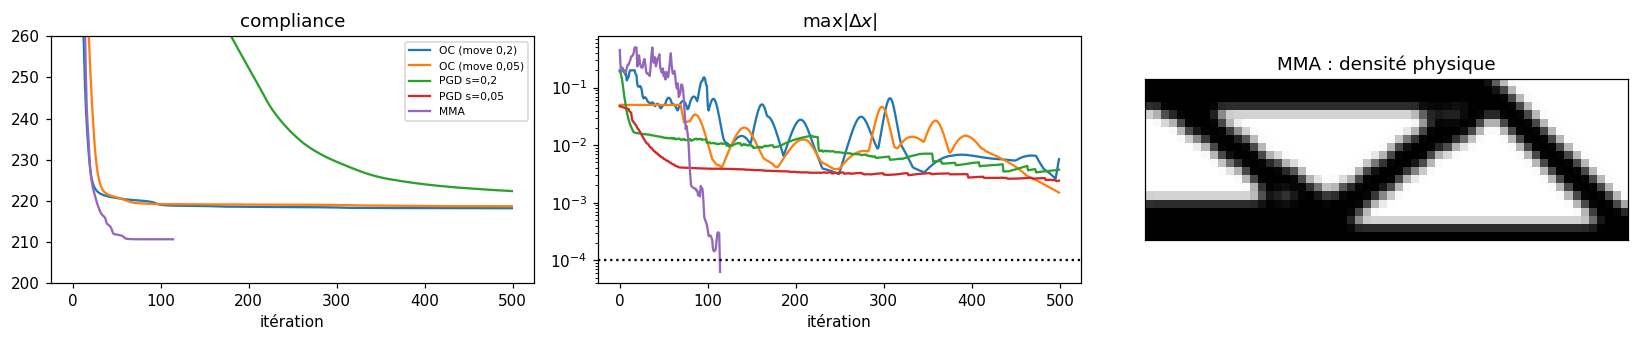

In [8]:
const = Schedule(p=(3.0, 3.0), beta=(0.0, 0.0), beta_s=(1.0, 1.0))
runs6 = {}
for nom, mk, norm in [("OC (move 0,2)", lambda: OC(), False), ("OC (move 0,05)", lambda: OC(move=0.05), False),
                      ("PGD s=0,2", lambda: PGD(0.2), False), ("PGD s=0,05", lambda: PGD(0.05), False),
                      ("MMA", lambda: MMA(), True)]:
    pb = ComplianceProblem("mbb", (60, 20), volfrac=0.5, R=1.5, normalize=norm)
    t0 = time.perf_counter()
    r = run(pb, mk(), const, max_iter=500, tol=1e-4)
    runs6[nom] = (pb, r, np.array([h["C"] for h in r.history]), time.perf_counter() - t0)
meilleur = min(C.min() for _, _, C, _ in runs6.values())
print(f"{'méthode':>16} | {'itérations':>10} | {'arrêt':>9} | {'C finale':>9} | {'écart / meilleure':>17} | {'it. à 1 %':>9} | {'g_V final':>9} | temps")
for nom, (pb, r, C, dt) in runs6.items():
    it1 = int(np.argmax(C < 1.01 * meilleur)) if (C < 1.01 * meilleur).any() else None
    print(f"{nom:>16} | {len(C):10d} | {r.stop_reason:>9} | {C[-1]:9.2f} | {100 * (C[-1] / meilleur - 1):16.2f}% | {str(it1):>9} | {r.history[-1]['g_V']:+9.1e} | {dt:.1f} s")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for nom, (pb, r, C, dt) in runs6.items():
    ax[0].plot(C, label=nom); ax[1].semilogy([h["dx"] for h in r.history], label=nom)
ax[0].set(ylim=(200, 260), xlabel="itération", title="compliance"); ax[0].legend(fontsize=7)
ax[1].set(xlabel="itération", title=r"$\max|\Delta x|$"); ax[1].axhline(1e-4, color="k", ls=":")
montre(ax[2], runs6["MMA"][0].rho_bar(torch.from_numpy(runs6["MMA"][1].x)).detach().numpy(), (60, 20), "MMA : densité physique")
plt.tight_layout(); plt.show()

In [9]:
# conditions KKT sur la solution de MMA (gradient recalculé sur le problème non normalisé)
pb, r, C, _ = runs6["MMA"]
pb_k = ComplianceProblem("mbb", (60, 20), volfrac=0.5, R=1.5)
x_t = torch.from_numpy(r.x).requires_grad_()
ev = pb_k.evaluate(x_t)
dJ = torch.autograd.grad(ev.J, x_t, retain_graph=True)[0].numpy()
dg = torch.autograd.grad(ev.g[0], x_t)[0].numpy()
k = kkt(r.x, dJ, np.array([ev.g[0].item()]), dg[None])
print(f"éléments libres : {int(((r.x > 1e-9) & (r.x < 1 - 1e-9)).sum())} sur {r.x.size} ; à 0 : {int((r.x <= 1e-9).sum())} ; à 1 : {int((r.x >= 1 - 1e-9).sum())}")
print(f"KKT : libres {k['libres']:.1e}, borne 0 : {k['borne_0']:.1e}, borne 1 : {k['borne_1']:.1e}, faisabilité {k['faisabilite']:.1e}, lambda {k['lambda'][0]:.2f}")

éléments libres : 27 sur 1200 ; à 0 : 592 ; à 1 : 581
KKT : libres 8.5e-07, borne 0 : 0.0e+00, borne 1 : 0.0e+00, faisabilité 0.0e+00, lambda 213.88


Sur la poutre :
- **MMA** converge réellement (critère $10^{-4}$ atteint en 115 itérations) vers une compliance de 210,7, atteint 1 % de sa valeur finale vers l'itération 45, et tient le volume à $10^{-10}$.
- **L'OC** (même déplacement limité à 0,2 que le notebook 8) ne converge pas en 500 itérations : la compliance plafonne autour de 218, soit 3,6 % au-dessus, avec une variation maximale qui reste de quelques $10^{-3}$ (oscillations). Réduire `move` à 0,05 l'adoucit mais ne change pas la compliance obtenue (218,7).
- **La descente projetée** dépend fortement du pas : avec $s=0{,}05$ elle est à 281, avec $s=0{,}2$ à 222, et aucune n'atteint MMA.
- **Le point trouvé par MMA vérifie KKT** (violations de l'ordre de la précision demandée). MMA et l'OC n'ont pas trouvé le même minimum local : MMA a un meilleur résultat *ici*, mais rien ne le garantit en général sur un problème non convexe.

(La valeur 210,7 n'est pas celle du benchmark C-OPT-02, qui compare l'OC au top88 après arrêt à $\max|\Delta x|<0{,}01$ ; il s'agit ici de deux optimiseurs poussés à convergence.)

## 7. MMA avec continuation : le reset est indispensable

Avec la continuation du notebook 9 ($\beta$ de 1 à 16, $p=3$, $R=3$), chaque changement d'étage modifie la fonction. MMA garde un **historique** (les deux dernières itérations et les asymptotes) ; après le changement, cet historique décrit l'ancienne fonction. Le contrat C-OPT-04 impose de le réinitialiser, et `run` le fait. Vérification en désactivant le reset, et comparaison avec l'OC et avec un $\beta$ fort d'emblée.

 continuation beta 1->16 | itérations |     arrêt |  C finale | dx final | % gris
          MMA avec reset |        383 | converged |    191.94 |   0.0010 |    2.6
          MMA sans reset |        400 |  max_iter |    230.72 |   0.0944 |    3.2
           OC (move 0,1) |        400 |  max_iter |    191.68 |   0.1000 |    2.8

         beta fixé (R=3) |  OC (move 0,1) |      MMA


                       4 |          217.6 |    217.7


                       8 |          568.9 |    200.3


                      16 |         6415.8 |    205.0


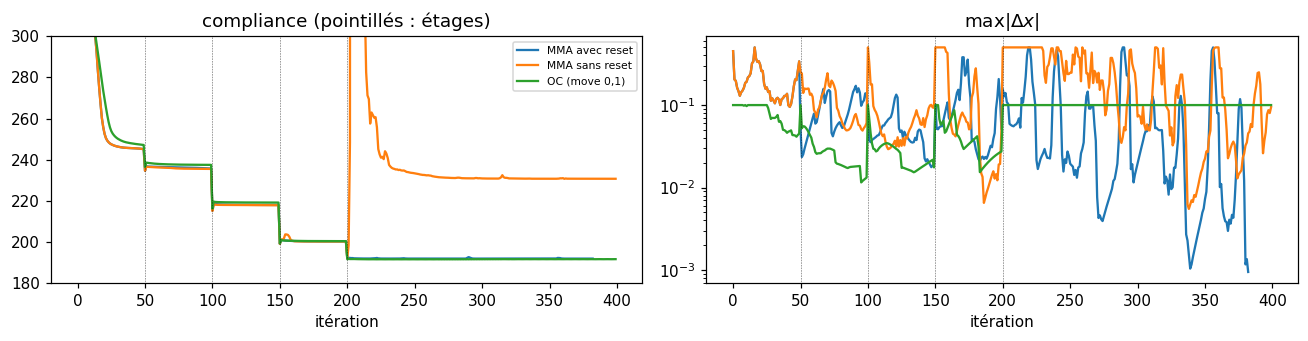

In [10]:
class MMASansReset(MMA):
    def reset(self):
        if not hasattr(self, "_k"):                      # l'initialisation passe par reset(), pas les étages
            super().reset()

def lance(mk, sch, norm, R=3.0, n_it=400):
    pb = ComplianceProblem("mbb", (60, 20), volfrac=0.5, R=R, normalize=norm)
    r = run(pb, mk(), sch, max_iter=n_it, tol=1e-3)
    return pb, r, np.array([h["C"] for h in r.history])

cont = Schedule(p=(3.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50)
runs7 = {}
for nom, mk, norm in [("MMA avec reset", MMA, True), ("MMA sans reset", MMASansReset, True), ("OC (move 0,1)", lambda: OC(move=0.1), False)]:
    runs7[nom] = lance(mk, cont, norm)
print(f"{'continuation beta 1->16':>24} | {'itérations':>10} | {'arrêt':>9} | {'C finale':>9} | {'dx final':>8} | {'% gris':>6}")
for nom, (pb, r, C) in runs7.items():
    rb = pb.rho_bar(torch.from_numpy(r.x)).detach().numpy()
    print(f"{nom:>24} | {len(C):10d} | {r.stop_reason:>9} | {C[-1]:9.2f} | {r.history[-1]['dx']:8.4f} | {100 * grise(rb):6.1f}")

print()
print(f"{'beta fixé (R=3)':>24} | {'OC (move 0,1)':>14} | {'MMA':>8}")
for beta in (4.0, 8.0, 16.0):
    sch = Schedule(p=(3.0, 3.0), beta=(beta, beta), beta_s=(1.0, 1.0))
    c_oc = lance(lambda: OC(move=0.1), sch, False, n_it=300)[2][-1]
    c_mma = lance(MMA, sch, True, n_it=300)[2][-1]
    print(f"{beta:24.0f} | {c_oc:14.1f} | {c_mma:8.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for nom, (pb, r, C) in runs7.items():
    ax[0].plot(C, label=nom); ax[1].semilogy([h["dx"] for h in r.history], label=nom)
for a_ in ax:
    for kk in range(1, 5): a_.axvline(50 * kk, color="k", lw=0.4, ls=":")
ax[0].set(ylim=(180, 300), xlabel="itération", title="compliance (pointillés : étages)"); ax[0].legend(fontsize=7)
ax[1].set(xlabel="itération", title=r"$\max|\Delta x|$")
plt.tight_layout(); plt.show()

- **Sans reset, MMA ne converge pas** : après 400 itérations sa compliance est à 230,7 (contre 191,9 avec reset) et la variation $\max|\Delta x|$ reste de l'ordre de 0,1. Les asymptotes héritées de l'ancien étage sont mal adaptées : au passage à l'étage final (itération 200) la compliance de la version sans reset bondit au-dessus de 300 avant de redescendre lentement (courbe). C'est la raison d'être du contrat C-OPT-04 et du `optimizer.reset()` de `run`.
- **Avec reset, MMA converge** (le critère d'arrêt est satisfait après l'étage final, 383 itérations) vers 191,9, comparable à l'OC (191,7) qui, lui, n'a pas convergé au sens du critère (déplacement maximal à la limite de 0,1).
- **Un $\beta$ élevé d'emblée** : l'OC échoue pour $\beta=8$ et 16 (notebook 9), MMA s'en sort bien mieux (205 à $\beta=16$), sans atteindre les 192 de la continuation. MMA diminue le besoin de continuation, il ne le supprime pas.

## 8. Un autre problème : minimiser le volume à compliance imposée

On échange les rôles : **minimiser le volume** $V(\bar\rho)$ sous la contrainte $\mathcal{C}\le\mathcal{C}_{\max}$, avec $\mathcal{C}_{\max}$ égale à la compliance optimale trouvée par MMA pour un volume de 50 %. C'est le problème « dual » : s'il n'y avait qu'un optimum, on devrait retrouver un volume proche de 50 %. Ici $\partial f/\partial x=\partial V/\partial x>0$ et $\partial g/\partial x\propto\partial\mathcal{C}/\partial x<0$ : **les signes sont ceux qui mettent l'OC en échec** (§1).

In [11]:
class VolumeSousCompliance:
    # même évaluation mécanique, mais f = volume et g = C / C_max - 1
    def __init__(self, pb, c_max): self.pb, self.c_max = pb, c_max
    def initial_design(self): return self.pb.initial_design()
    def set_continuation(self, params): self.pb.set_continuation(params)
    def evaluate(self, x):
        r = self.pb.evaluate(x)
        return SimpleNamespace(J=r.terms["vol"], g=[r.terms["C"] / self.c_max - 1.0], terms={"C": r.terms["C"], "vol": r.terms["vol"]})

c_max = runs6["MMA"][2][-1]
print(f"C_max = {c_max:.3f} (compliance optimale de MMA à volume 0,5)")
for nom, opt in [("OC", OC()), ("MMA", MMA())]:
    pb = ComplianceProblem("mbb", (60, 20), volfrac=0.5, R=1.5)
    r = run(VolumeSousCompliance(pb, c_max), opt, const, max_iter=300, tol=1e-4)
    h = r.history[-1]
    print(f"{nom:>4} : {len(r.history):3d} itérations, arrêt « {r.stop_reason} », volume final {h['vol']:.4f}, "
          f"compliance {h['C']:.3g}, contrainte g = {h['g_V']:+.2e}")

C_max = 210.669 (compliance optimale de MMA à volume 0,5)
  OC :   4 itérations, arrêt « converged », volume final 0.0000, compliance 1.26e+11, contrainte g = +5.98e+08


 MMA : 182 itérations, arrêt « converged », volume final 0.5146, compliance 211, contrainte g = +7.53e-10


L'OC **s'effondre** : en quatre itérations le volume tombe à 0 et la compliance explose ($10^{11}$), et pourtant `run` répond « converged » parce que le critère d'arrêt ne voit que la variation de $\mathbf x$, qui est nulle sur le design vide. Retenez-le : **le critère d'arrêt ne vérifie pas la faisabilité** ; il faut toujours lire la contrainte finale dans l'historique (c'est ce que font les tests, C-OPT-03). MMA, lui, résout le problème : volume 0,5146 avec $\mathcal{C}=\mathcal{C}_{\max}$ à $10^{-9}$ près. Le volume obtenu est proche de 0,5 mais pas égal : le problème n'est pas convexe, les deux formulations ne partagent pas exactement le même minimum local.

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| OC suppose une contrainte, $\partial f\le0$, $\partial g>0$ ; sinon il échoue sans erreur | §1, §8 |
| Les KKT avec bornes ($r=0$ libre, $r\ge0$ en 0, $r\le0$ en 1) donnent un critère indépendant de l'optimiseur | `kkt` (notebook) |
| La descente projetée est simple mais lente et sensible au pas | `PGD` (notebook), §3, §6 |
| MMA : approximation convexe séparable, asymptotes mobiles, sous-problème par le dual ($m$ variables), invariance d'échelle | `optim/mma.py`, §4 |
| MMA retrouve trois solutions connues ($10^{-9}$ à $10^{-16}$) dont deux contraintes contre SLSQP | §5, tests `test_optim` |
| Sur la poutre, MMA converge (115 it., $\mathcal{C}=210{,}7$, KKT, volume à $10^{-10}$) là où l'OC oscille | §6 |
| Sans reset aux changements de continuation, MMA ne converge pas | §7, C-OPT-04 |
| $\mathcal{C}$ en contrainte et le volume en objectif : OC s'effondre, MMA réussit | §8 |

**Limites à retenir.**
- **MMA simple, pas GCMMA** : pas de boucle interne qui garantisse la convergence globale (on peut avoir des itérations non monotones) ; pas de variables élastiques : si le sous-problème est infeasible (contraintes incompatibles dans la région de confiance), le dual diverge et le code retourne le point le plus proche de la faisabilité (borne $10^{15}$ sur le multiplicateur). Pour les deux contraintes (L-BFGS-B) la faisabilité n'est atteinte qu'à la tolérance du dual.
- **Un minimum local** : MMA et OC n'ont pas trouvé le même (§6, §8). Les comparaisons de compliance entre méthodes sont des comparaisons de minima locaux.
- **Le critère d'arrêt ne vérifie pas la faisabilité** (§8).
- **Les gradients doivent être exacts** : MMA exploite les gradients bien plus que l'OC ; l'adjoint (notebook 7) est validé par différences finies et `gradcheck`.
- **Non testé ici** : plusieurs contraintes sur un problème de structure réel (viendra avec le couplage, leçon 17), objectifs bruités.

**Pour expérimenter.** (i) Au §4, rapprochez les asymptotes initiales (`MMA(asyinit=0.2)`) et comparez la vitesse sur la poutre. (ii) Au §6, changez `move` de MMA (0,1 ; 0,5 ; 1,0). (iii) Au §5, ajoutez une troisième contrainte aux deux de SLSQP. (iv) Au §7, essayez `every=25` : le reset à chaque étage coûte-t-il en itérations ? (v) Au §8, prenez $\mathcal{C}_{\max}$ 10 % plus grand : quel volume obtient-on ?

*Suite : leçon 11 (anisotropie : le matériau orthotrope). Voir le [plan des leçons](README.md).*